# Lecture 19 — Debugging and profiling with a coding assistant

We want to follow the concentrations of three chemicals through an oscillation. When we try to follow the first sharp rise, our simulation returns `nan`. We will reproduce the failure, find the step that produced it and check whether another solver gives an accurate trajectory.

Open this notebook with a Python 3 kernel with NumPy, SciPy and Matplotlib installed. **Restart Kernel and Run All** runs the live examples. The code and initial conditions are in the cells below. The quoted questions can be given to a coding assistant during the lecture.

In [1]:
import cProfile
import pstats
from statistics import median
from time import perf_counter
import traceback

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

## 1. Where does the simulation first go wrong?

The Oregonator models an oscillating chemical reaction. The vector `y` holds three scaled concentrations, `a`, `e` and `r`. The function `rhs(t, y)` returns their rates of change. We start at `y0 = [1, 2, 3]` and follow the reaction from $t=0$ to $t=30$, an interval that contains the first sharp rise.

In [2]:
def rhs(t, y):
    a, e, r = y
    s, q, w, f = 77.27, 8.375e-6, 0.161, 1.0
    return np.array([
        s * (e - e * a + a - q * a * a),
        (-e - e * a + f * r) / s,
        w * (a - r),
    ])


y0 = np.array([1.0, 2.0, 3.0])

We first choose a fixed step $h=0.01$. One RK4 step evaluates `rhs` at four trial states. We save the resulting concentrations in one row per time step, starting with the initial state in row zero.

In [3]:
def rk4_step(t, y, h):
    k1 = rhs(t, y)
    k2 = rhs(t + h / 2, y + h / 2 * k1)
    k3 = rhs(t + h / 2, y + h / 2 * k2)
    k4 = rhs(t + h, y + h * k3)
    return y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)


def fixed_rk4(y0, h, end=30.0):
    steps = round(end / h)  # all intervals below contain a whole number of steps
    times = h * np.arange(steps + 1)
    states = np.empty((steps + 1, len(y0)))
    states[0] = y0
    for i in range(steps):
        states[i + 1] = rk4_step(times[i], states[i], h)
    return times, states

In [4]:
with np.errstate(over="warn", invalid="warn"):
    times, states = fixed_rk4(y0, 0.01)
print("Steps:", len(times) - 1)
print("Final concentrations:", states[-1])

Steps: 3000
Final concentrations: [nan nan nan]


/var/folders/hc/d14d998d3rv6_7vdcjskjrxc0000gp/T/ipykernel_38101/1944056055.py:5: RuntimeWarning: overflow encountered in scalar multiply
  s * (e - e * a + a - q * a * a),
/var/folders/hc/d14d998d3rv6_7vdcjskjrxc0000gp/T/ipykernel_38101/1944056055.py:6: RuntimeWarning: overflow encountered in scalar multiply
  (-e - e * a + f * r) / s,
/var/folders/hc/d14d998d3rv6_7vdcjskjrxc0000gp/T/ipykernel_38101/1944056055.py:6: RuntimeWarning: invalid value encountered in scalar subtract
  (-e - e * a + f * r) / s,
/var/folders/hc/d14d998d3rv6_7vdcjskjrxc0000gp/T/ipykernel_38101/1944056055.py:7: RuntimeWarning: invalid value encountered in scalar subtract
  w * (a - r),


### Traceback (notes §2.2)

The last row contains three `nan` values. We want to know which operation failed first. Keeping the model and step size fixed, we ask NumPy to raise an exception on overflow or invalid arithmetic. The cell prints the traceback of that exception so that **Run All** can continue.

> Reproduce the failure. Which RK4 stage called the model, and which operation overflowed? Show the evidence before suggesting a change.

The notes show the same calculation in [`experiments/bz_raise.py`](https://github.com/borisbolliet/attractor/blob/lecture-19-start/experiments/bz_raise.py) at `lecture-19-start`. Here the calls lead back to the notebook cells defining `rk4_step` and `rhs`.

In [5]:
try:
    with np.errstate(over="raise", invalid="raise"):
        fixed_rk4(y0, 0.01)
except FloatingPointError:
    traceback.print_exc()

Traceback (most recent call last):
  File "/var/folders/hc/d14d998d3rv6_7vdcjskjrxc0000gp/T/ipykernel_38101/3088407399.py", line 3, in <module>
    fixed_rk4(y0, 0.01)
    ~~~~~~~~~^^^^^^^^^^
  File "/var/folders/hc/d14d998d3rv6_7vdcjskjrxc0000gp/T/ipykernel_38101/1532527555.py", line 15, in fixed_rk4
    states[i + 1] = rk4_step(times[i], states[i], h)
                    ~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/hc/d14d998d3rv6_7vdcjskjrxc0000gp/T/ipykernel_38101/1532527555.py", line 4, in rk4_step
    k3 = rhs(t + h / 2, y + h / 2 * k2)
  File "/var/folders/hc/d14d998d3rv6_7vdcjskjrxc0000gp/T/ipykernel_38101/1944056055.py", line 5, in rhs
    s * (e - e * a + a - q * a * a),
             ~~^~~
FloatingPointError: overflow encountered in scalar multiply


During the third stage, `k3`, the product `e * a` overflowed. How did its operands get so large? We can inspect the trajectory we saved in the first run. A row is finite only if all three concentrations in it are finite.

In [6]:
finite_rows = np.isfinite(states).all(axis=1)
first_bad = np.flatnonzero(~finite_rows)[0]
print("step    time        a           e           r")
for i in range(first_bad - 3, first_bad + 1):
    a, e, r = states[i]
    print(f"{i:4d}  {times[i]:6.2f}  {a:10.3g}  {e:10.3g}  {r:10.3g}")

step    time        a           e           r
2042   20.42    6.27e+04        1.01         177
2043   20.43   -2.73e+07   -4.36e+03        4.71
2044   20.44   -1.94e+56   -3.09e+52   -8.06e+26
2045   20.45        -inf         nan        -inf


At $t=20.43$, `a` is already negative, two steps before the first non-finite row at $t=20.45$. For these equations a solution starting with positive concentrations stays non-negative. The numerical solution had therefore gone wrong before the overflow.

Does a smaller step move the failure? We can try a step ten times smaller without changing the equations.

In [7]:
with np.errstate(over="ignore", invalid="ignore"):
    smaller_times, smaller_states = fixed_rk4(y0, 0.001)
bad = np.flatnonzero(~np.isfinite(smaller_states).all(axis=1))
print("First non-finite time with h=0.001:", smaller_times[bad[0]] if bad.size else "none")

First non-finite time with h=0.001: 23.28


Reducing $h$ delays the failure. To see whether we can avoid it without choosing a single small step for the entire interval, we can let a solver choose its own step sizes.

## 2. Why does RK45 take so long?

SciPy's RK45 estimates the local error of each attempted step. It can reject an attempt and try again with a smaller step. We use relative and absolute tolerances of $10^{-6}$ and let RK45 choose the initial step. With no output times requested, `sol.t` contains the initial time and one time per accepted step.

In [8]:
def solve(method, tol=1e-6, output_times=None):
    sol = solve_ivp(rhs, (0.0, 30.0), y0, method=method,
                    rtol=tol, atol=tol, t_eval=output_times)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol


profiler = cProfile.Profile()
rk45 = profiler.runcall(solve, "RK45")
stats = pstats.Stats(profiler).strip_dirs().sort_stats("tottime")
_ = stats.print_stats(8)

         9813413 function calls (9813411 primitive calls) in 4.439 seconds

   Ordered by: internal time
   List reduced from 118 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
   174765    1.617    0.000    3.111    0.000 rk.py:14(rk_step)
  1048592    0.816    0.000    1.018    0.000 1944056055.py:1(rhs)
   149982    0.533    0.000    4.213    0.000 rk.py:111(_step_impl)
  1048592    0.212    0.000    1.310    0.000 base.py:23(fun_wrapped)
  1048593    0.204    0.000    0.204    0.000 {built-in method numpy.array}
  1048592    0.141    0.000    1.451    0.000 base.py:156(fun)
   174765    0.139    0.000    0.146    0.000 rk.py:105(_estimate_error)
   174768    0.125    0.000    0.248    0.000 _linalg.py:2615(norm)




`tottime` measures time in the function's own code. `cumtime` includes functions it calls. Find the `ncalls` entries for `rk_step`, which attempts one step, and for our model function `rhs`.

> Use the profile to predict how many times RK45 evaluated the model. Count rejected attempts as well as accepted steps. Check your prediction against `rk45.nfev`, SciPy's count of right-hand-side evaluations.

In SciPy's RK45 each call to `rk_step` attempts one step and makes six evaluations. Two further evaluations initialise this run. We can check that explanation using the numbers from our own profile.

In [9]:
rows = stats.get_stats_profile().func_profiles
attempts = int(rows["rk_step"].ncalls)
accepted = len(rk45.t) - 1
predicted = 6 * attempts + 2
print(f"{attempts:,} attempts × 6 + 2 = {predicted:,} evaluations")
print(f"rhs calls in the profile: {rows['rhs'].ncalls}")
print(f"Evaluations reported by SciPy: {rk45.nfev:,}")
print(f"{accepted:,} accepted steps and {attempts - accepted:,} rejected attempts")
assert predicted == int(rows["rhs"].ncalls) == rk45.nfev

174,765 attempts × 6 + 2 = 1,048,592 evaluations
rhs calls in the profile: 1048592
Evaluations reported by SciPy: 1,048,592
149,982 accepted steps and 24,783 rejected attempts


The model is inexpensive to evaluate once. The cost comes from evaluating it over a million times. In this reaction a small perturbation can decay much faster than the concentrations we want to follow. An explicit solver such as RK45 can then need a small step for stability even during a slow part of the trajectory. This is a **stiff** problem. LSODA can switch to an implicit method during stiff phases. Does it take fewer steps there?

## 3. Can we get an accurate trajectory in less time?

We compare RK45 and LSODA on the same interval with the same tolerances. For timing we make one untimed call followed by three repetitions and report the median. We run these calls outside the profiler because recording each call adds overhead.

In [10]:
def median_seconds(function, *args):
    function(*args)
    elapsed = []
    for _ in range(3):
        start = perf_counter()
        function(*args)
        elapsed.append(perf_counter() - start)
    return median(elapsed)


lsoda = solve("LSODA")
print("method    accepted steps   evaluations   median (s)")
for method, sol in [("RK45", rk45), ("LSODA", lsoda)]:
    seconds = median_seconds(solve, method)
    print(f"{method:7}   {len(sol.t) - 1:12,}   {sol.nfev:11,}   {seconds:10.4f}")

method    accepted steps   evaluations   median (s)


RK45           149,982     1,048,592       3.2361
LSODA              836         1,733       0.0033


Where do their step sizes differ? The lower panel shows each accepted step's length against its starting time. The concentration in the upper panel tells us which part of the reaction we are looking at.

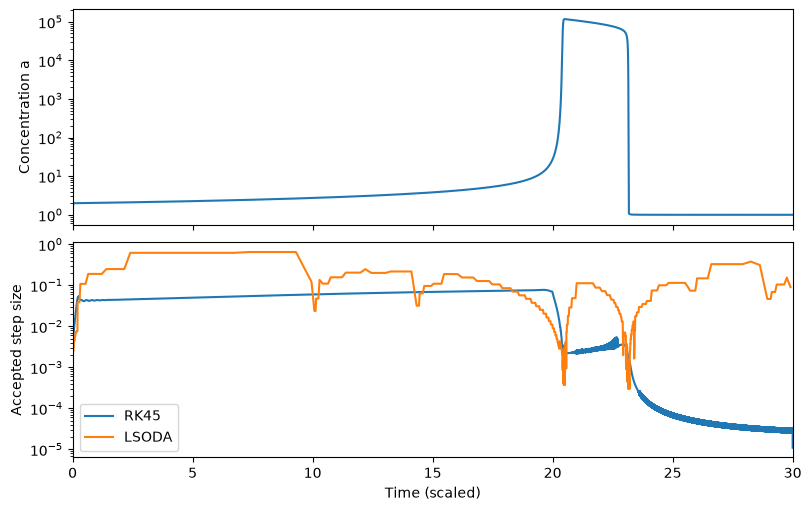

In [11]:
fig, (concentration, steps) = plt.subplots(2, 1, sharex=True, figsize=(8, 5), layout="constrained")
concentration.semilogy(lsoda.t, lsoda.y[0])
concentration.set_ylabel("Concentration a")
for label, sol in [("RK45", rk45), ("LSODA", lsoda)]:
    steps.semilogy(sol.t[:-1], np.diff(sol.t), label=label)
steps.set(xlabel="Time (scaled)", ylabel="Accepted step size", xlim=(0, 30))
steps.legend()
plt.show()

After the sharp rise, LSODA takes longer steps while RK45 continues to take small ones. The package example in notes §4.2 supplies LSODA with the derivatives of the model rates (its Jacobian). Here we let LSODA estimate those derivatives, so its step and evaluation counts can differ.

A plot could still hide an error near the peak. To check accuracy we compare **all three concentrations** with a tighter Radau reference at 601 common times. Passing the times in `t_eval` asks SciPy to return values there while choosing its own internal steps.

Before making the comparison, we set the allowed difference at each saved value to $10^{-6}+10^{-4}|y_{\rm ref}|$. This is our requirement for the **returned trajectory**. The solver tolerances control its internal estimate of local error.

In [12]:
common_times = np.linspace(0.0, 30.0, 601)
reference = solve("Radau", 1e-11, common_times)
loose = solve("LSODA", 1e-6, common_times)

allowed = 1e-6 + 1e-4 * np.abs(reference.y)
error_ratio = np.abs(loose.y - reference.y) / allowed
species, point = np.unravel_index(error_ratio.argmax(), error_ratio.shape)
print(f"Largest difference / allowed difference: {error_ratio.max():.2f}")
print(f"For {('a', 'e', 'r')[species]} at t = {common_times[point]:.2f}")

Largest difference / allowed difference: 47.09
For a at t = 23.15


A ratio above 1 means the difference exceeds our allowance. We now tighten LSODA's solver tolerances to $10^{-10}$ and keep the same comparison. As a check on the reference, we repeat the Radau run at $10^{-12}$ and require the two reference trajectories to agree more closely.

In [13]:
refined = solve("Radau", 1e-12, common_times)
np.testing.assert_allclose(reference.y, refined.y, rtol=1e-6, atol=1e-8)

candidate = solve("LSODA", 1e-10, common_times)
assert np.isfinite(candidate.y).all()
np.testing.assert_allclose(candidate.y, reference.y, rtol=1e-4, atol=1e-6)
print(f"All {candidate.y.size} saved concentrations pass the comparison.")

for method, tol in [("RK45", 1e-6), ("LSODA", 1e-10)]:
    result = solve(method, tol, common_times)
    passed = np.allclose(result.y, reference.y, rtol=1e-4, atol=1e-6)
    seconds = median_seconds(solve, method, tol, common_times)
    print(f"{method:5}  tolerance {tol:g}  passes: {passed}  median: {seconds:.4f} s")

All 1803 saved concentrations pass the comparison.


RK45   tolerance 1e-06  passes: True  median: 3.4408 s
LSODA  tolerance 1e-10  passes: True  median: 0.0226 s


> Would you accept the proposed change to LSODA? Use the timing for the settings that passed our accuracy check. Which comparison would you keep as a regression test?

For the project version, the traceback in notes §2.2 comes from [`experiments/bz_raise.py`](https://github.com/borisbolliet/attractor/blob/lecture-19-start/experiments/bz_raise.py) at `lecture-19-start`. The completed package and its tests are at [`lecture-19`](https://github.com/borisbolliet/attractor/tree/lecture-19).

## Optional experiments

To run the following experiments, change `run_extensions` to `True` and rerun this section. The first needs only NumPy. The other two use `line_profiler` and `numba` if installed.

In [14]:
run_extensions = False

### Fixed-step sweep (notes §2.4)

How small must the fixed step be to finish **this run**? The last row uses 1.5 million RK4 steps. A finite final state alone gives no measure of its accuracy.

In [15]:
if run_extensions:
    print("       h       steps   first non-finite t")
    with np.errstate(over="ignore", invalid="ignore"):
        for h in (1e-2, 1e-3, 1e-4, 2e-5):
            t, y = fixed_rk4(y0, h)
            bad = np.flatnonzero(~np.isfinite(y).all(axis=1))
            first = f"{t[bad[0]]:.4f}" if bad.size else "none"
            print(f"{h:8g}   {len(t) - 1:9,}   {first:>18}")

### Line profiling (notes §5.7)

Which lines are expensive when we evaluate the RK4 stability polynomial on an array? We give each power its own line so that the profiler can time it separately. The final check evaluates the same polynomial by repeated multiplication and addition.

In [16]:
def rk4_powers(z):
    square = z ** 2
    cube = z ** 3
    quartic = z ** 4
    return 1 + z + square / 2 + cube / 6 + quartic / 24


if run_extensions:
    try:
        from line_profiler import LineProfiler
    except ImportError:
        print("To run this example, install line_profiler in this kernel.")
    else:
        z = np.linspace(-4.0, 0.0, 1_000_001)
        lines = LineProfiler(rk4_powers)
        powers = lines.runcall(rk4_powers, z)
        lines.print_stats(output_unit=1e-3)
        horner = 1 + z * (1 + z * (1/2 + z * (1/6 + z/24)))
        np.testing.assert_allclose(horner, powers, rtol=1e-13, atol=1e-14)

### Compiling the same RK4 loop (notes §5.3)

Changing the solver reduced the number of steps. Here we keep the same steps and use Numba to compile the functions defined above. We stop at $t=20$, where both runs stay finite with $h=10^{-4}$. The first compiled call includes compilation. Later calls reuse the compiled code.

In [17]:
if run_extensions:
    try:
        from numba import njit
        from numba.extending import register_jitable
    except ImportError:
        print("To run this example, install numba in this kernel.")
    else:
        register_jitable(rhs)
        register_jitable(rk4_step)
        compiled_run = njit(fixed_rk4)
        args = (y0, 1e-4, 20.0)
        start = perf_counter()
        _, compiled_states = compiled_run(*args)
        print(f"First compiled call: {perf_counter() - start:.3f} s")
        _, python_states = fixed_rk4(*args)
        np.testing.assert_allclose(compiled_states, python_states, rtol=1e-12)
        print(f"Compiled median: {median_seconds(compiled_run, *args):.3f} s")
        print(f"Python median:   {median_seconds(fixed_rk4, *args):.3f} s")